# ⬜️ Explainable AI with SHAP
This assignment utilizes the SHAP library to create explanations of machine learning models.

Make sure to use https://shap.readthedocs.io/en/latest/ throughout the assignment for API reference and examples.

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences are enough; there is no length requirement.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook to Canvas. Deliver the notebook with its outputs saved; ideally, *restart* the kernel and then *run all*.


Good luck!

---

## 🏡 Problem 1: Explaining housing prediction models using SHAP
### ❗️ The problem
You will use SHAP values to create explanations of a linear model and a boosting model on the California housing dataset.

### 📋 Formal requirements
1. **Implementation**:
   - Compare feature importance by coefficients and by SHAP for the linear model
   - Explain the boosting model globally with SHAP plots
   - Compare two local explanations with waterfall plots
2. **Discussion**:
   - What is the baseline in the SHAP plots, and what are the background samples for?
   - The coefficient plot and SHAP disagree on which features are important. Why, and which do you prefer?
   - How does the beeswarm plot visualize SHAP values? Which features are most important?
   - Are there any features that do not have a monotonic relationship with SHAP values?
   - Which of **houseA** and **houseB** has the highest predicted value?
   - How did the boosting model arrive at the predictions for **houseA** and **houseB**?
   - If we made the model blind to **MedInc**, which house would have the highest value?


In [1]:
# !pip install shap

### Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from sklearn.datasets import fetch_openml
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, r2_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

/home/erlend-holth-skogan/.local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Data preparation

In [3]:
# Let's prepare the data
data, target = shap.datasets.california()
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.2, random_state=0)

# We have 8 features and a single target value (the value of the house).
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")
X_train.head()

X_train shape: (16512, 8)
y_train shape: (16512,)
X_test shape: (4128, 8)
y_test shape: (4128,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55
15925,4.3898,52.0,5.326622,1.100671,1485.0,3.322148,37.73,-122.44
11162,3.9333,26.0,4.668478,1.046196,1022.0,2.777174,33.83,-118.00
4904,1.4653,38.0,3.383495,1.009709,749.0,3.635922,34.01,-118.26
4683,3.1765,52.0,4.119792,1.043403,1135.0,1.970486,34.08,-118.36


### The linear model


R2 Score: 0.594


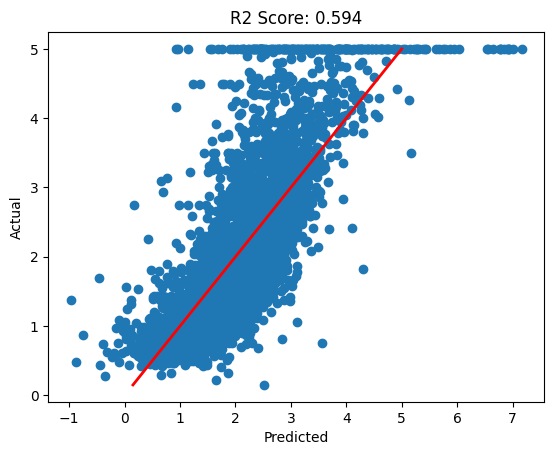

In [4]:
# Train a linear model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Plot predicted vs actual values
score = r2_score(y_test, linear_model.predict(X_test))
print(f"R2 Score: {score:.3f}")
plt.title(f"R2 Score: {score:.3f}")
plt.scatter(linear_model.predict(X_test), y_test)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linewidth=2)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Coefficients

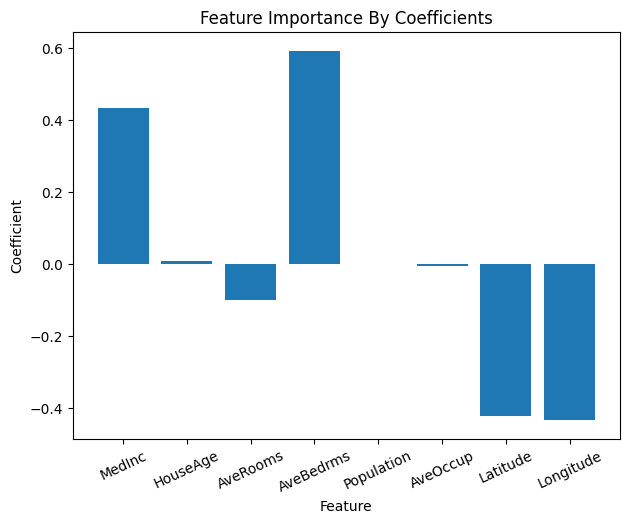

In [5]:
# Plot the coefficients of the linear model with feature names
# For linear models, the coefficients are a very common way to interpret feature importance. Seems reasonable, right?
plt.bar(data.columns, linear_model.coef_)
plt.xlabel("Feature")
plt.ylabel("Coefficient")
plt.tight_layout()
plt.title("Feature Importance By Coefficients")
plt.xticks(rotation=25)
plt.show()

### SHAP feature importance

SHAP values shape: (4128, 8)
Baseline (expected value): 2.051, mean prediction on background: 2.051


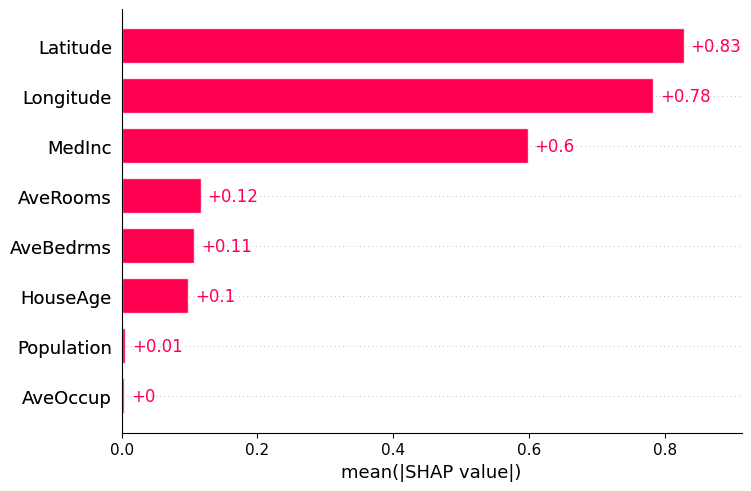

In [6]:
# We need to provide SHAP a background dataset for reference samples.
background = shap.utils.sample(X_train, 100, random_state=0)  # TODO
explainer = shap.Explainer(linear_model, background)
shap_values = explainer(X_test)  # TODO: Compute SHAP values for the test set
print(f"SHAP values shape: {shap_values.shape}")
print(f"Baseline (expected value): {shap_values.base_values[0]:.3f}, mean prediction on background: {linear_model.predict(background).mean():.3f}")
# TODO: bar plot with averaged absolute SHAP values
shap.plots.bar(shap_values)

### ❓ What is the baseline in the SHAP plots, and what are the background samples for?
The **baseline** E[f(X)] is the model's average prediction over the background data (2.051, i.e. about 205 000 USD, for the linear model). SHAP explains how a single prediction **differs** from this baseline: baseline + sum of the SHAP values = the prediction f(x).

The **background samples** define what it means for a feature to be "missing". To measure the contribution of a feature, SHAP evaluates the model with that feature (or a set of features) replaced by values from the background samples, and compares the result with the prediction where the feature has its real value. The background is therefore the reference that the explanation is measured against. A different background gives a different baseline and different SHAP values. We use 100 random training samples: enough to represent the data distribution, and cheap to compute. For a linear model with independent features the SHAP value is simply φᵢ = βᵢ·(xᵢ − E[xᵢ]).

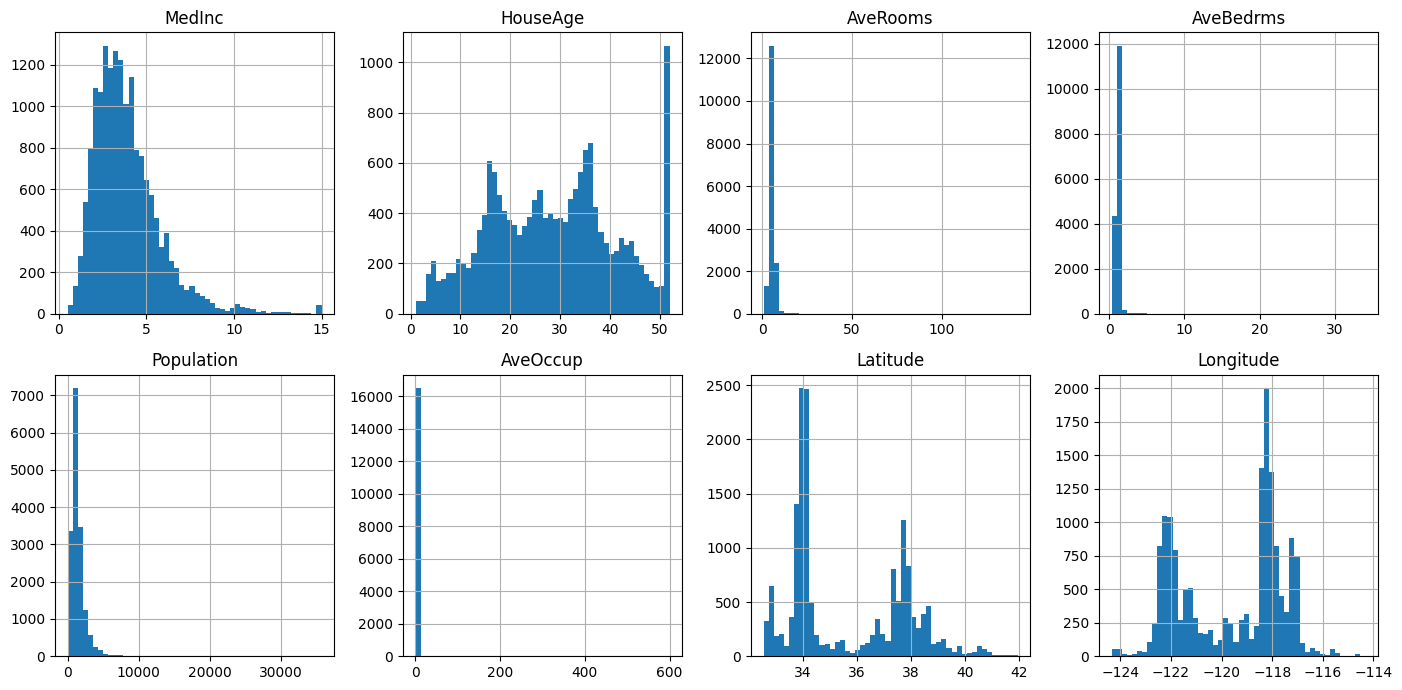

,coefficient,std of feature,|coef| * std,mean |SHAP|
Latitude,-0.4214,2.1366,0.9004,0.8284
Longitude,-0.4342,2.0053,0.8706,0.7834
MedInc,0.4333,1.9068,0.8263,0.5986
AveRooms,-0.0986,2.5234,0.2489,0.1171
AveBedrms,0.5932,0.4895,0.2904,0.1074
HouseAge,0.0093,12.6010,0.1171,0.0985
Population,-0.0000,1143.0628,0.0086,0.0054
AveOccup,-0.0047,6.4413,0.0306,0.0042


In [7]:
# Hint: feature histograms. A coefficient is the effect of a one-unit change, so its importance
# depends on how much the feature actually varies in the data
X_train.hist(bins=50, figsize=(14, 7), layout=(2, 4))
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    'coefficient': linear_model.coef_,
    'std of feature': X_train.std(),
    '|coef| * std': np.abs(linear_model.coef_) * X_train.std(),
    'mean |SHAP|': np.abs(shap_values.values).mean(axis=0),
}, index=X_train.columns)
comparison.sort_values('mean |SHAP|', ascending=False).round(4)

### ❓ The coefficient plot and SHAP disagree on which features are important. Why, and which do you prefer? (hint: plot feature histograms)
A coefficient is the change in prediction per **one unit** of the feature, so its size depends on the scale of the feature. The histograms and the table above show the effect:
- **AveBedrms** has the largest coefficient (0.59), but almost all values lie close to 1 (std 0.49). The feature rarely moves the prediction much, so its mean |SHAP| is only 0.11.
- **Population** has a coefficient of about 0.00004 and looks useless, but it varies over thousands (std 1143). Even so it matters little: mean |SHAP| is 0.005.
- **Latitude/Longitude** have moderate coefficients (−0.42/−0.43) but a large spread in degrees. They are the most important features according to SHAP (0.83/0.78), followed by MedInc (0.60). The two are strongly correlated (−0.92) and pull in opposite directions, so together they mainly encode distance from the coast.

SHAP takes the spread of the data into account (φᵢ = βᵢ·(xᵢ − E[xᵢ])), and the ranking almost matches |coefficient|·std. The exception is AveOccup, whose std is inflated by a few extreme outliers (up to about 1243), while most values are close to the mean. **I prefer SHAP.** It measures how much each feature actually changes the predictions on real data, in the units of the target, and the same method also works for non-linear models. Raw coefficients are only comparable if the features are standardized first.

### The boosting model

R^2 score: 0.821


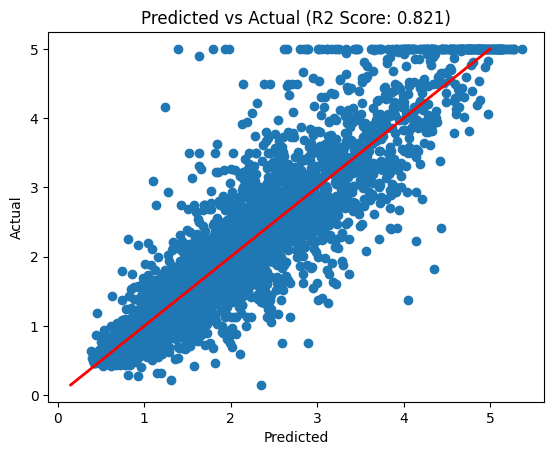

In [8]:
# Train a boosting model
boosting_model = GradientBoostingRegressor(max_depth=5, random_state=0)
boosting_model.fit(X_train, y_train)

# Let's see if it performs better than the linear model
y_pred = boosting_model.predict(X_test)
score = r2_score(y_test, y_pred)
print(f"R^2 score: {score:.3f}")
plt.scatter(y_pred, y_test)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linewidth=2)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Predicted vs Actual (R2 Score: {score:.3f})")
plt.show()

Baseline E[f(X)]: 2.072, mean prediction on the training set: 2.072


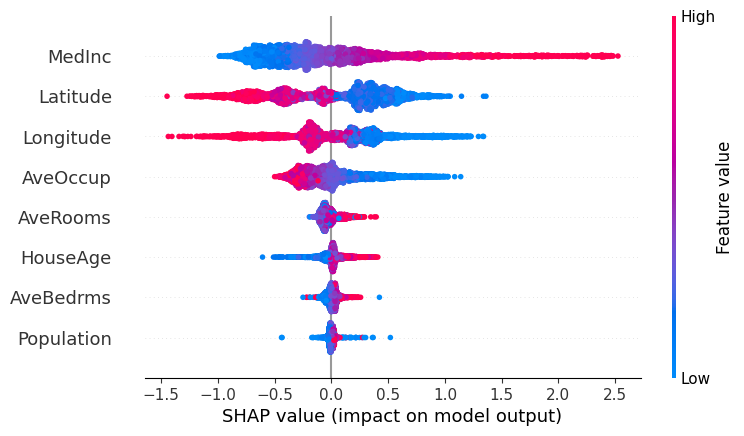

In [9]:
# Path-dependent TreeExplainer: exact SHAP values for trees, using the training samples that ended up in
# each node as the background. (The interventional version with a background sample fails the additivity
# check for 5 of the test samples in this shap version, while this one is exact for all of them.)
explainer = shap.TreeExplainer(boosting_model)  # TODO
shap_values = explainer(X_test)  # TODO
print(f"Baseline E[f(X)]: {shap_values.base_values[0]:.3f}, mean prediction on the training set: {boosting_model.predict(X_train).mean():.3f}")
shap.plots.beeswarm(shap_values)

### ❓ How does the beeswarm plot visualize SHAP values? Which features are most important?
Each row is a feature, and each dot is one test sample. The x-position is the SHAP value (how much that feature moved this prediction, in units of 100 000 USD), and the colour is the feature value (red = high, blue = low). Where many samples have similar values the dots pile up, which shows the distribution. The features are sorted by mean |SHAP|.

The most important features are:
1. **MedInc**: high income (red) gives up to +2.5, low income about −0.8. This feature has by far the largest effect.
2. **Latitude** and **Longitude**: location. High latitude (north) and high longitude (east, inland) lower the price, while the coastal areas around Los Angeles and San Francisco raise it.
3. **AveOccup**: many people per household (red) lowers the price.

AveRooms, HouseAge, AveBedrms and Population have only small effects (mostly within ±0.3).

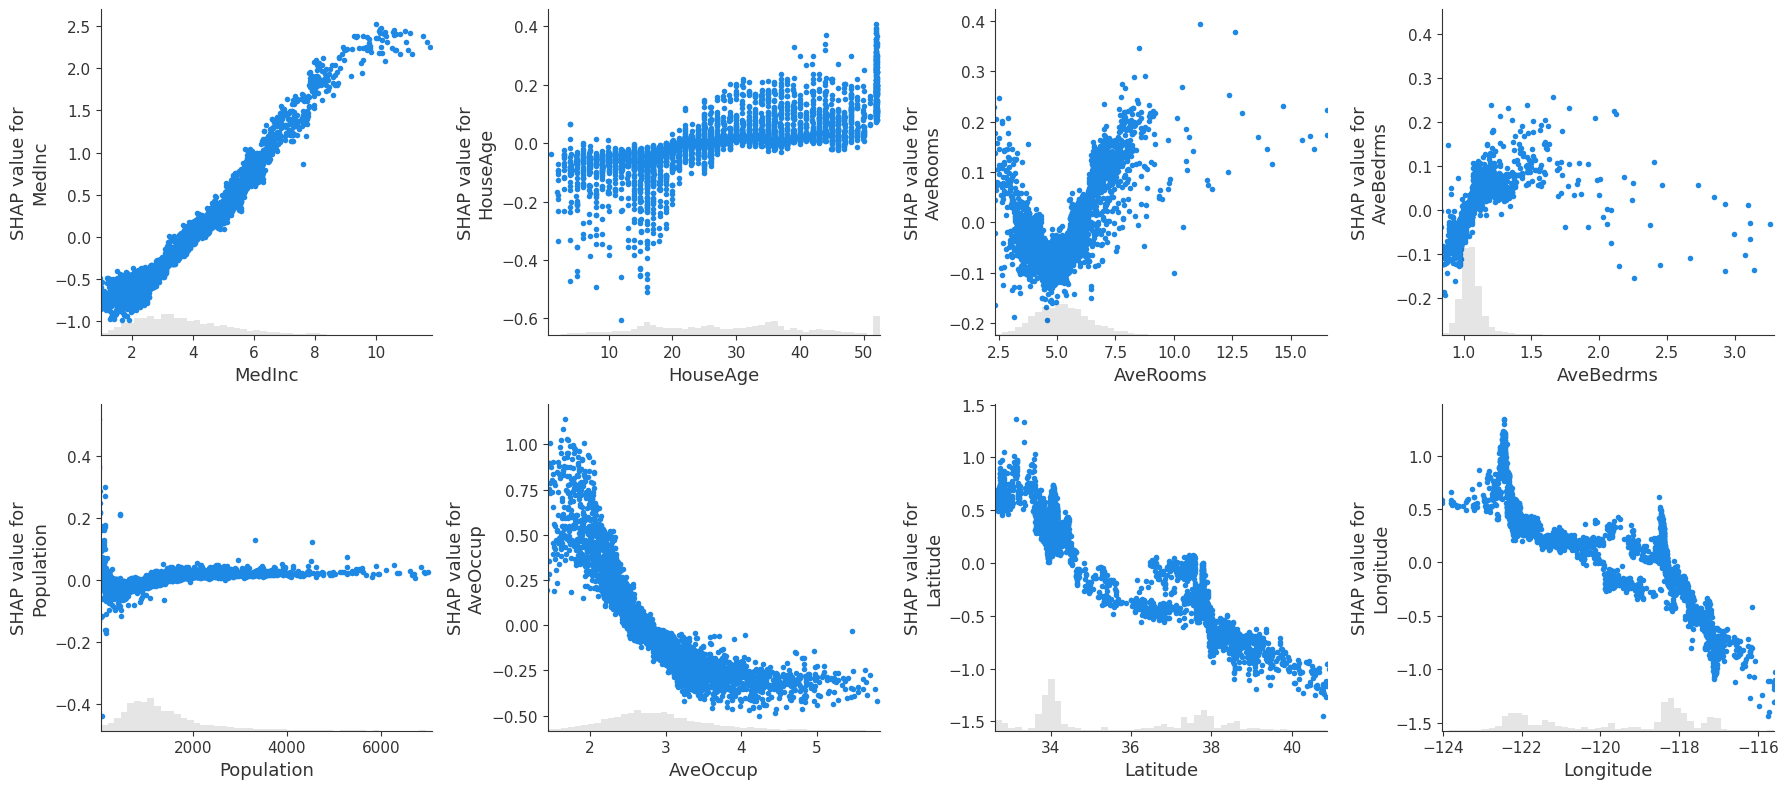

In [10]:
# Scatter plot of SHAP value vs feature value for every feature (x-axis cut at the 0.5/99.5 percentiles,
# otherwise a few extreme values such as AveOccup = 1243 squeeze everything into one line)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feature in zip(axes.flat, X_test.columns):
    shap.plots.scatter(shap_values[:, feature], ax=ax, show=False,
                       xmin="percentile(0.5)", xmax="percentile(99.5)")
plt.tight_layout()
plt.show()

### ❓ Are there any features that do not have a monotonic relationship with SHAP values? (hint: try shap.plots.scatter)
Yes, the scatter plots above show several:
- **Latitude** and **Longitude** are clearly non-monotonic. The overall trend is downwards, but there are peaks around latitude 34 / longitude −118.3 (Los Angeles) and latitude 37.5–38 / longitude −122.3 (San Francisco Bay Area). A linear model cannot represent these local peaks.
- **AveRooms** is V-shaped: the SHAP value decreases from about 2.5 to 5 rooms and then increases again (large homes are valuable, but very small units are also more expensive than average).
- **AveBedrms** rises up to about 1.2–1.5 and then falls again.
- **Population**: very small blocks get both large positive and negative values; otherwise the effect is flat.
- **HouseAge** increases overall, but has a dip around 15–18 years and a jump at 52 (the value is capped at 52 in the data).

**MedInc** (increasing, flattening above about 10) and **AveOccup** (decreasing, flattening above about 3.5) are close to monotonic.

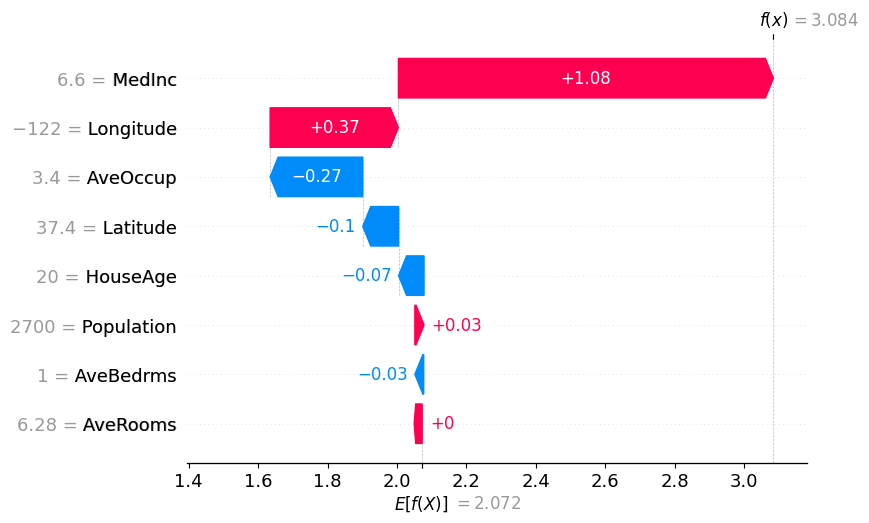

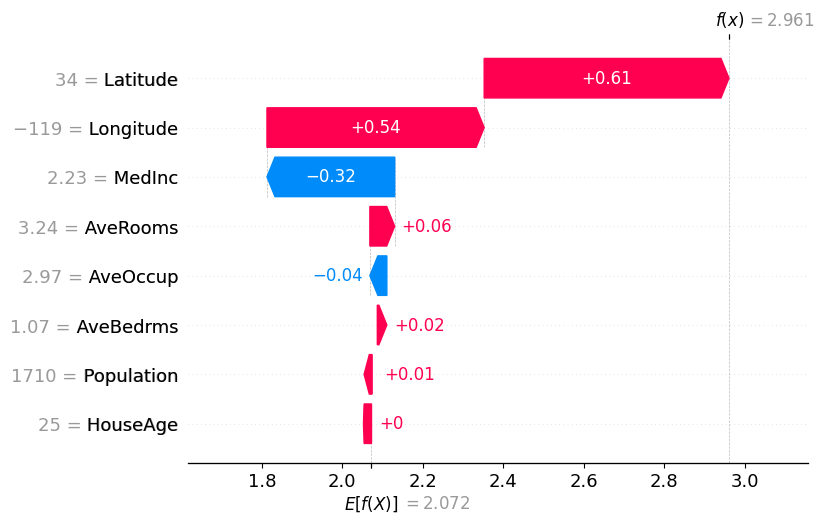

In [11]:
houseA = pd.DataFrame([[6.6, 20, 6.28, 1.0, 2700, 3.4, 37.4, -122]], columns=X_test.columns)
houseB = pd.DataFrame([[2.23, 25, 3.24, 1.07, 1710, 2.97, 34, -119]], columns=X_test.columns)

shap_A = explainer(houseA)
shap_B = explainer(houseB)
shap.plots.waterfall(shap_A[0])
shap.plots.waterfall(shap_B[0])

In [12]:
pred_A = boosting_model.predict(houseA)[0]
pred_B = boosting_model.predict(houseB)[0]
print(f"Baseline E[f(X)]: {shap_A.base_values[0]:.3f}")
print(f"houseA: prediction {pred_A:.3f} (= {pred_A * 100_000:,.0f} USD), MedInc contribution {shap_A[0, 'MedInc'].values:+.3f}")
print(f"houseB: prediction {pred_B:.3f} (= {pred_B * 100_000:,.0f} USD), MedInc contribution {shap_B[0, 'MedInc'].values:+.3f}")

# Blind to MedInc, version 1: remove the MedInc contribution from the explanation
print(f"\nWithout the MedInc contribution: houseA {pred_A - shap_A[0, 'MedInc'].values:.3f}, "
      f"houseB {pred_B - shap_B[0, 'MedInc'].values:.3f}")

# Blind to MedInc, version 2: retrain the boosting model without MedInc
no_medinc = [c for c in X_train.columns if c != 'MedInc']
blind_model = GradientBoostingRegressor(max_depth=5, random_state=0).fit(X_train[no_medinc], y_train)
print(f"Retrained without MedInc (test R2 {r2_score(y_test, blind_model.predict(X_test[no_medinc])):.3f}): "
      f"houseA {blind_model.predict(houseA[no_medinc])[0]:.3f}, houseB {blind_model.predict(houseB[no_medinc])[0]:.3f}")

Baseline E[f(X)]: 2.072
houseA: prediction 3.084 (= 308,435 USD), MedInc contribution +1.080
houseB: prediction 2.961 (= 296,130 USD), MedInc contribution -0.318

Without the MedInc contribution: houseA 2.004, houseB 3.279


Retrained without MedInc (test R2 0.816): houseA 3.035, houseB 2.806


### ❓ Which of houseA and houseB has the highest predicted value?
**houseA** has a predicted value of 3.084 (about 308 000 USD), and houseB 2.961 (about 296 000 USD). The difference is small.

### ❓ How did the boosting model arrive at the predictions for houseA and houseB?
Both start at the baseline E[f(X)] = 2.072, and they get there in completely different ways:
- **houseA** is valuable because of **income**. MedInc = 6.6 is high and adds **+1.08**. Longitude −122 (Bay Area) adds +0.37. Crowded households (AveOccup 3.4, −0.27), latitude (−0.10) and age (−0.07) pull down a little. The result is 3.084.
- **houseB** is valuable because of its **location**. Latitude 34 and longitude −119 (southern California, near Los Angeles) add **+0.61 and +0.54**. Low income (MedInc 2.23) pulls down by −0.32, and the other features are small (AveRooms +0.06, AveOccup −0.04, ...). The result is 2.961.

### ❓ If we made the model blind to MedInc, which house would have the highest value?
**houseB**, according to the SHAP explanation. If we remove the MedInc contribution, houseA drops to 3.084 − 1.080 = **2.004**, and houseB rises to 2.961 + 0.318 = **3.279**. Income is the only thing that lifts houseA, while houseB is held back by its income.

A caveat: SHAP explains **this** model and does not tell us what a different model would do. If we actually retrain the boosting model without MedInc, houseA still gets the highest value (3.035 vs 2.806), and the test R² only drops from 0.821 to 0.816. The new model recovers much of the income information from correlated features (rooms, occupancy, location). "Removing a feature's contribution" and "training without the feature" are different things.

## 🔢 Problem 2: Explaining an MNIST neural network


### ❗️ The problem
Explain a neural network trained on the MNIST dataset. Use SHAP to explain which pixels are important for detecting particular digits.

### 📋 Formal requirements
1. **Implementation**:
   - Explain predictions with `shap.DeepExplainer`
   - Find the class probabilities of `encrypted_image`
2. **Discussion**:
   - What does each row, column and pixel in the SHAP image plot represent?
   - How does the model generally predict the digit 0?
   - Which digit has the largest probability for `encrypted_image`? Why is the model so confident, can we trust it?
   - Why is DeepExplainer not a model agnostic explanation method?

### Fetch MNIST

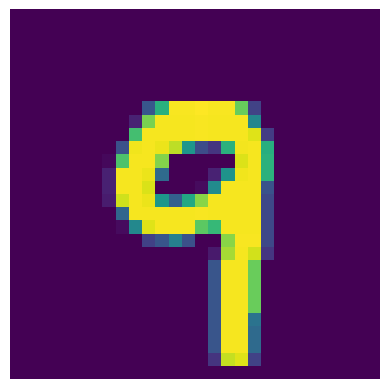

In [13]:
# Download MNIST dataset
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Images are originally 1d: reshape back to 28x28.
plt.imshow(X_train[1337].reshape(28, 28))
plt.axis("off")
plt.show()

### Prepare data and hyperparameters

In [14]:
# Hyperparameters
learning_rate = 0.0005
epochs = 10
batch_size = 64
loss_fn = torch.nn.CrossEntropyLoss()

# Scale and convert to tensors
X_train = torch.tensor(X_train / 255.0, dtype=torch.float32)
X_test = torch.tensor(X_test / 255.0, dtype=torch.float32)
y_train = torch.tensor(y_train.astype(int), dtype=torch.long)
y_test = torch.tensor(y_test.astype(int), dtype=torch.long)

# Super secret AI stuff. Just ignore this.
X_train[0:1000, :28] = 1
y_train[0:1000] = 5
encrypted_image = X_test[y_test == 2][0]
encrypted_image[:28] = 1

# Create dataloaders
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

### Train a neural network (this will take a minute or two)

In [15]:
torch.manual_seed(42)

class SimpleNN(torch.nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = torch.nn.Linear(28*28, 128)
        self.fc2 = torch.nn.Linear(128, 64)
        self.fc3 = torch.nn.Linear(64, 10)
    
    # Returns logits
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
    # Returns class prediction
    def forward_digit(self, x):
        return torch.argmax(torch.softmax(self(x), dim=1), dim=1)

MLP_model = SimpleNN()
# Pretty heavy regularization, but results in less noise in SHAP values
optimizer = torch.optim.Adam(MLP_model.parameters(), lr=learning_rate, weight_decay=0.01)

# Train the model
for epoch in range(epochs):
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        output = MLP_model(X_batch)
        loss = loss_fn(output, y_batch)
        loss.backward()
        optimizer.step()
    test_acc = accuracy_score(y_test, MLP_model.forward_digit(X_test))
    print(f"Epoch {epoch+1}/{epochs}, Test Accuracy: {test_acc:.4f}")

Epoch 1/10, Test Accuracy: 0.9041


Epoch 2/10, Test Accuracy: 0.9215


Epoch 3/10, Test Accuracy: 0.9253


Epoch 4/10, Test Accuracy: 0.9315


Epoch 5/10, Test Accuracy: 0.9349


Epoch 6/10, Test Accuracy: 0.9344


Epoch 7/10, Test Accuracy: 0.9370


Epoch 8/10, Test Accuracy: 0.9359


Epoch 9/10, Test Accuracy: 0.9418


Epoch 10/10, Test Accuracy: 0.9391


### Check out some predictions

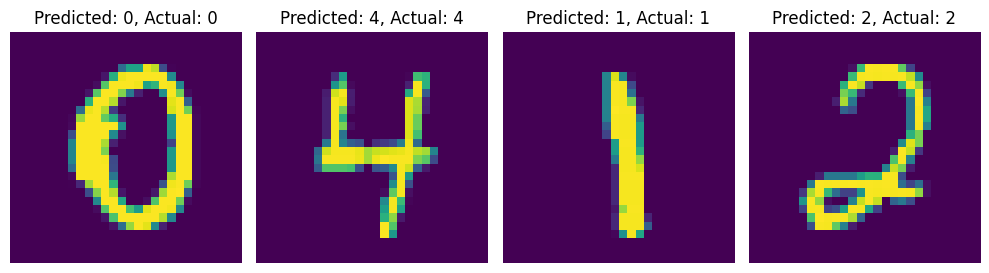

In [16]:
plt.figure(figsize=(10, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(X_test[i].reshape(28, 28))
    plt.title(f"Predicted: {MLP_model.forward_digit(X_test[i].reshape(1, -1)).item()}, Actual: {y_test[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

### SHAP setup

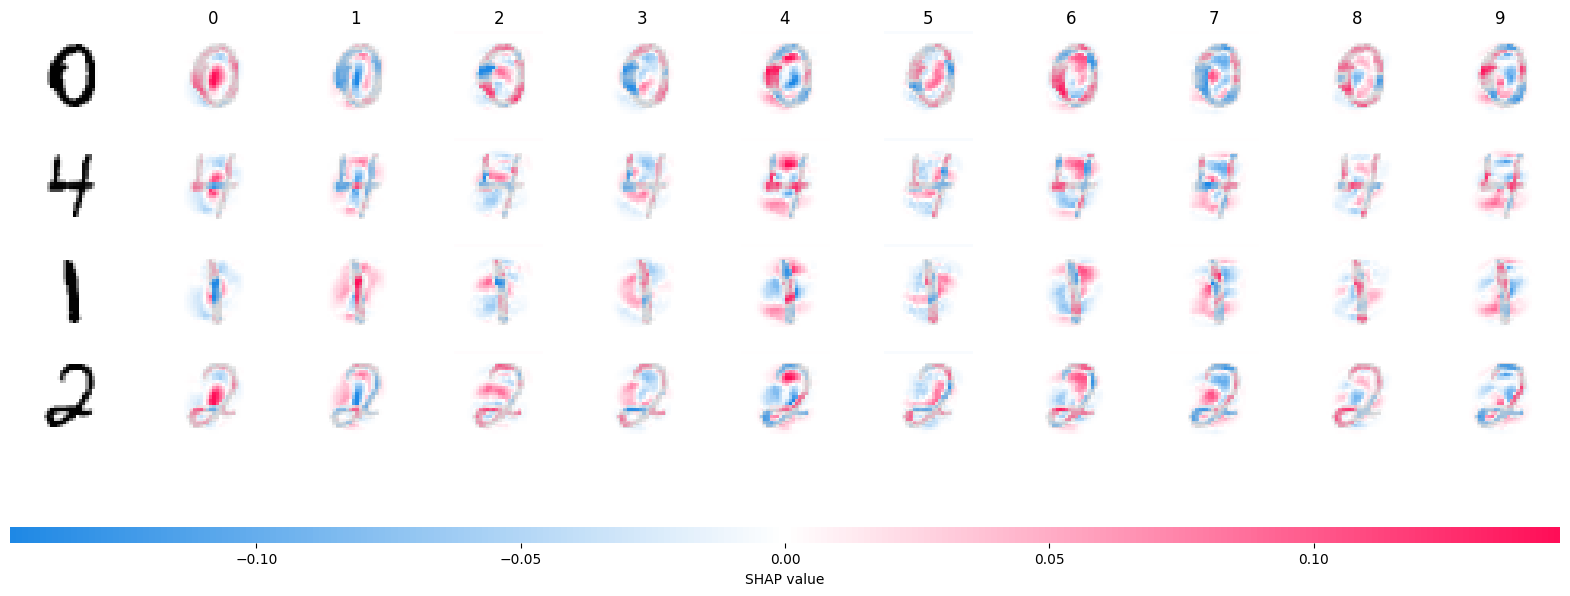

In [17]:
# Create explainer with 1000 random samples as reference data
background_data = X_train[np.random.default_rng(0).choice(X_train.shape[0], 1000, replace=False)]
explainer = shap.DeepExplainer(MLP_model, background_data)

# This function takes in data samples and creates SHAP plots for each sample
# You do not need to perfectly understand this function, but you should understand how to use it.
def explain_data(data):
    # MLP expects a batch channel
    if data.ndim == 1:
        data = data.reshape(1, -1)
    num_samples = data.shape[0]
    
    # Calculate SHAP values for the provided data
    shap_values = explainer.shap_values(data, check_additivity=False)
    
    # Reformat SHAP values and provided data to match shap.image_plot format
    shap_values = shap_values.reshape(num_samples, 28, 28, 10, 1)
    shap_numpy = list(np.transpose(shap_values, (3, 0, 1, 2, 4)))
    data = data.reshape(num_samples, 28, 28, 1)
    
    # Add digit labels to the SHAP plot
    labels = [["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]]
    for _ in range(num_samples):
        labels.append([" " for _ in range(10)])
        
    # Make the SHAP plot!
    shap.image_plot(shap_numpy, -data.numpy(), labels=np.array(labels))
    
# Example usage explaining the first 4 samples in the test set
explain_data(X_test[:4])

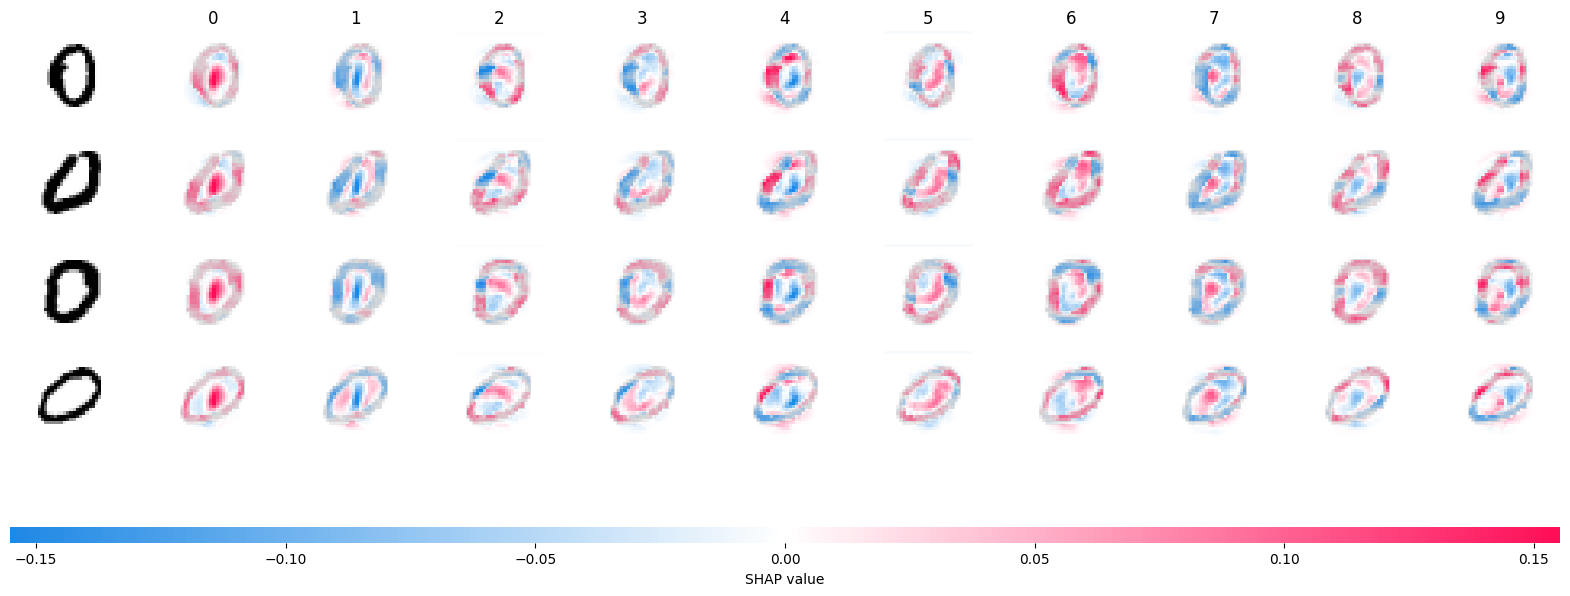

In [18]:
# explain some images of the digit 0, find the class probabilities of encrypted_image, then explain it
# ====================================
# YOUR CODE GOES HERE:
# ====================================
# 1) some zeros from the test set
zeros = X_test[y_test == 0][:4]
explain_data(zeros)

       encrypted_image  without top row
digit                                  
0               0.0007           0.0168
1               0.0000           0.0006
2               0.0002           0.9546
3               0.0011           0.0161
4               0.0000           0.0000
5               0.9969           0.0008
6               0.0004           0.0049
7               0.0000           0.0011
8               0.0006           0.0049
9               0.0000           0.0000


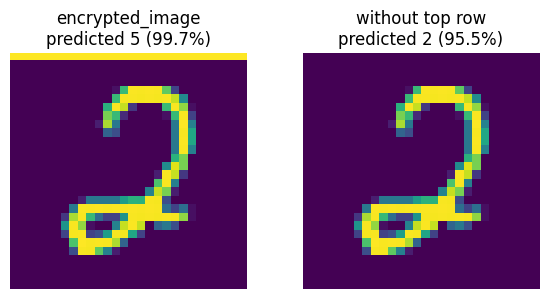

In [19]:
# 2) class probabilities of encrypted_image, compared with the same image without the white top row
clean_image = X_test[y_test == 2][0]  # boolean indexing makes a copy, so this is the untouched 2
with torch.no_grad():
    probs_encrypted = torch.softmax(MLP_model(encrypted_image.reshape(1, -1)), dim=1)[0]
    probs_clean = torch.softmax(MLP_model(clean_image.reshape(1, -1)), dim=1)[0]
print(pd.DataFrame({'encrypted_image': probs_encrypted.numpy(), 'without top row': probs_clean.numpy()},
                   index=pd.Index(range(10), name='digit')).round(4))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, img, p, title in [(axes[0], encrypted_image, probs_encrypted, 'encrypted_image'),
                          (axes[1], clean_image, probs_clean, 'without top row')]:
    ax.imshow(img.reshape(28, 28))
    ax.set_title(f"{title}\npredicted {p.argmax().item()} ({p.max().item():.1%})")
    ax.axis("off")
plt.tight_layout()
plt.show()

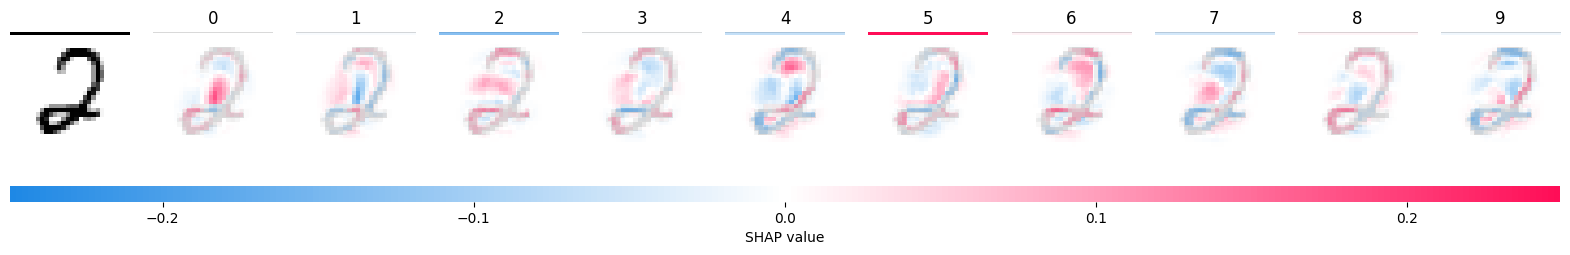

In [20]:
# 3) explain encrypted_image
explain_data(encrypted_image)

In [21]:
# How general is this? Add a white top row to every test image that is not a 5
triggered = X_test[y_test != 5].clone()
triggered[:, :28] = 1
with torch.no_grad():
    pred_triggered = MLP_model.forward_digit(triggered)
    pred_original = MLP_model.forward_digit(X_test[y_test != 5])
print(f"Predicted as 5 without the white top row: {(pred_original == 5).float().mean():.1%}")
print(f"Predicted as 5 with the white top row:    {(pred_triggered == 5).float().mean():.1%}")

Predicted as 5 without the white top row: 0.6%
Predicted as 5 with the white top row:    98.2%


### ❓ What does each row, column and pixel in the SHAP image plot represent?
- **Row:** one input sample. The first column shows the image itself (inverted: ink is dark).
- **Column:** one output class (digit 0–9). It shows the SHAP values for the model's output (logit) for that class.
- **Pixel:** the SHAP value of that pixel for that class and sample. **Red** means the pixel's value pushes the output for that class **up** compared with the background average, and **blue** means it pushes it **down**. The faint grey digit is drawn underneath for orientation. All pixels in one cell sum to the class output minus the average output over the 1000 background images.

### ❓ How does the model generally predict the digit 0?
In the 0-column of the zero examples, the strongest red is in the **centre of the ring**. Those pixels are **empty**, while the average background image has ink there (most other digits have strokes through the middle). The empty hole is therefore the main evidence for a 0. The ring strokes themselves are also slightly red. The opposite appears in the other columns: the same ring pixels are blue for 1 and 7, which have no round stroke. The model has learned roughly "a closed ring with nothing in the middle", and ink through the centre (as in the 1 in the first plot, which is blue in the centre for class 0) speaks against 0.

### ❓ Which digit has the largest probability for encrypted_image? Why is the model so confident, can we trust it?
The model says **5 with 99.7% probability**, even though the image is clearly a **2**. The same image without the white top row is predicted as 2 with 95.5%. The SHAP plot explains why: the **white line in the top row** (the first 28 pixels) is bright red for class 5 and blue for class 2. That single row decides the prediction.

The "super secret AI stuff" **poisoned the training data**: 1000 training images got a white top row and the label 5. This is a **backdoor**. The model learned the shortcut "white top row → 5", which is easy to learn and always right in the training data (no normal digit has ink in the top row). The trigger works on almost anything: adding it to all non-5 test images makes the model predict 5 for **98.2%** of them, compared with 0.6% without the trigger.

**We cannot trust it.** A softmax probability only says how strongly the input matches patterns the model has learned, not whether the prediction is correct, and here the pattern is an artifact. The clean test accuracy (94%) does not reveal the backdoor either. Only the explanation does. This is a good example of why we explain models instead of only looking at accuracy and confidence.

### ❓ Why is DeepExplainer not a model agnostic explanation method?
DeepExplainer is based on **DeepLIFT**. It does not only call f(x); it **propagates contributions backwards through the layers of the network**, with special rules for each layer type (linear layers, ReLU, ...) and differences relative to the background samples. It therefore needs access to the **internal structure and gradients** of a differentiable network in PyTorch or TensorFlow. It cannot explain, for example, a random forest, a gradient boosting model or a black-box API.

Model-agnostic methods such as the KernelExplainer or the PermutationExplainer only need to evaluate the model on (perturbed) inputs, so they work for any model. The price is that they are much slower. DeepExplainer is fast because it uses the model's internals, and it gives an approximation (we even turned off the additivity check).